# Simple loop graph

In [7]:
import random
from typing import TypedDict

from langgraph.graph import END, START, StateGraph


class AgentState(TypedDict):
    lower_bound: int
    upper_bound: int
    guesses: list[int]
    attempts: int
    target_number: int



def setup_node(state: AgentState) -> AgentState:
    '''Inititalize graph state properly'''    

    state['lower_bound'] = 1
    state['upper_bound'] = 20
    state['guesses'] = []
    state['attempts'] = 0

    if not(state['lower_bound'] <= state['target_number']  <= state['upper_bound']):
        raise ValueError('Please provide a target number that is ')

    return state

def guessing_node(state: AgentState) -> AgentState:
    '''Guesses a number between upper and lower bound'''

    print(f'Guessing a number in range {state['lower_bound']} - {state['upper_bound']}')
    guessed_number = random.randint(state['lower_bound'], state['upper_bound'])    

    state['attempts'] += 1
    state['guesses'].append(guessed_number)

    print(f'Guessed number is {guessed_number}')

    return state

def hint_node(state: AgentState) -> AgentState:
    '''Determine whether to guess more numbers or not'''

    guessed_number = state['guesses'][-1]

    if guessed_number == state['target_number']:
        pass

    elif guessed_number > state['target_number']:
        print('Guessed number is higher than target')
        state['upper_bound'] = guessed_number - 1

    else:
        print('Guessed number is lower than target')
        state['lower_bound'] = guessed_number + 1
    
    return state

def decide_looping(state: AgentState): 
    '''Decides whether to continue looping or end'''

    guessed_number = state['guesses'][-1]

    if guessed_number == state['target_number']:
        print('Guessed number matches target number!')
        return 'end'

    elif state['attempts'] > 7:
        print('Reached max number of guesses!')
        return 'end'

    else:
        return 'continue'


graph = StateGraph(AgentState)

graph.add_node('setup_node', setup_node)
graph.add_node('guessing_node', guessing_node)

graph.add_node('hint_node', hint_node)

graph.add_edge(START, 'setup_node')
graph.add_edge('setup_node','guessing_node')
graph.add_edge('guessing_node','hint_node')

graph.add_conditional_edges(
    'hint_node',
    decide_looping,
    {
        'end': END,
        'continue': 'guessing_node'
    }
)

agent = graph.compile()
    



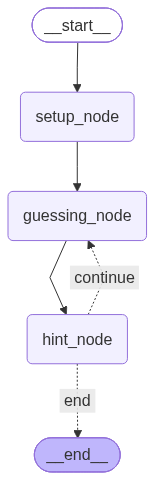

In [8]:
from IPython.display import Image, display

display(Image(agent.get_graph().draw_mermaid_png()))

In [9]:
result = agent.invoke({'target_number': 10, 'lower_bound': 1, 'upper_bound': 20, 'attempts': 0, "guesses": [], })

result

Guessing a number in range 1 - 20
Guessed number is 9
Guessed number is lower than target
Guessing a number in range 10 - 20
Guessed number is 12
Guessed number is higher than target
Guessing a number in range 10 - 11
Guessed number is 10
Guessed number matches target number!


{'lower_bound': 10,
 'upper_bound': 11,
 'guesses': [9, 12, 10],
 'attempts': 3,
 'target_number': 10}